In [13]:
%pip install -q numpy librosa scikit-learn tensorflow matplotlib seaborn transformers torch gTTS

Note: you may need to restart the kernel to use updated packages.


In [21]:
import os
import glob
import numpy as np
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

In [22]:
#  Load Audio Files from the RAVDESS Dataset
DATASET_PATH = r"D:\Audio_Speech_Actors_01-24"
audio_files = glob.glob(
    os.path.join(DATASET_PATH, "**", "*.wav"),
    recursive=True
)

print("Total audio files:", len(audio_files))

Total audio files: 1440


In [32]:
# Extract Audio File Paths and Corresponding Emotion Labels
emotion_map = {
    "01": "neutral", "02": "calm",
    "03": "happy", "04": "sad",
    "05": "angry", "06": "fearful",
    "07": "disgust", "08": "surprised"
}

files, labels = [], []

for file in audio_files:
    parts = os.path.basename(file).split("-")

    if len(parts) == 7 and parts[0] == "03" and parts[1] == "01":
        files.append(file)
        labels.append(emotion_map[parts[2]])

print("Speech recordings:", len(files))

Speech recordings: 1440


In [34]:
# Extract MFCC Features for Audio Classification
def extract_mfcc(file):
    audio, sr = librosa.load(file, sr=22050)
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=40)

    if mfcc.shape[1] < 174:
        mfcc = np.pad(mfcc, ((0, 0), (0, 174 - mfcc.shape[1])))
    else:
        mfcc = mfcc[:, :174]

    return mfcc

X = np.array([extract_mfcc(f) for f in files])
encoder = LabelEncoder()
y = encoder.fit_transform(labels)

X = X[..., np.newaxis]

print("Feature shape:", X.shape)
print("Number of emotions:", len(encoder.classes_))

Feature shape: (1440, 40, 174, 1)
Number of emotions: 8


In [35]:
#Split the Dataset into Training and Testing Sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1152
Testing samples: 288


In [36]:
#  Design and Compile the CNN Model for Emotion Classification
model = Sequential([
    tf.keras.layers.Input(shape=(40, 174, 1)),
    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(8, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 40, 174, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 87, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 27520)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     1,761,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,780,680 (6.79 MB)

 Trainable params: 1,780,680 (6.79 MB)

 Non-trainable params: 0 (0.00 B)

In [37]:
#Train the CNN Model Using Audio Features
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    callbacks=[EarlyStopping(patience=5, restore_best_weights=True)]
)

Epoch 1/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step - accuracy: 0.1325 - loss: 9.2526 - val_accuracy: 0.1299 - val_loss: 2.0784
Epoch 2/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - accuracy: 0.1325 - loss: 2.0786 - val_accuracy: 0.1688 - val_loss: 2.0661
Epoch 3/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.1336 - loss: 2.0772 - val_accuracy: 0.1299 - val_loss: 2.0761
Epoch 4/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.1346 - loss: 2.0762 - val_accuracy: 0.1299 - val_loss: 2.0749
Epoch 5/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.1346 - loss: 2.0745 - val_accuracy: 0.1299 - val_loss: 2.0738
Epoch 6/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.1477 - loss: 2.0701 - val_accuracy: 0.1948 - val_loss: 2.0517
Epoch 7/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step - accuracy: 0.1792 - loss: 2.0522 - val_accuracy: 0.1818 - val_loss: 2.0265
Epoch 8/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - accuracy: 0.1922 - loss: 2.0147 - val_accuracy: 0.1905 - v

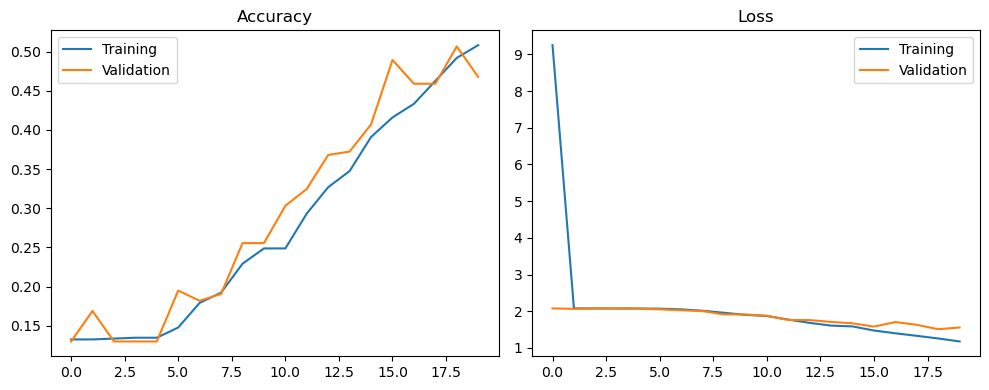

In [38]:
#Plot Training and Validation Accuracy and Loss
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Test Accuracy: 0.4340277777777778
F1 Score: 0.3584461036015722
              precision    recall  f1-score   support

       angry       0.54      0.58      0.56        38
        calm       0.47      0.71      0.56        38
     disgust       0.39      0.42      0.41        38
     fearful       0.52      0.56      0.54        39
       happy       0.33      0.08      0.12        39
     neutral       0.00      0.00      0.00        19
         sad       0.21      0.11      0.14        38
   surprised       0.40      0.79      0.53        39

    accuracy                           0.43       288
   macro avg       0.36      0.41      0.36       288
weighted avg       0.38      0.43      0.38       288



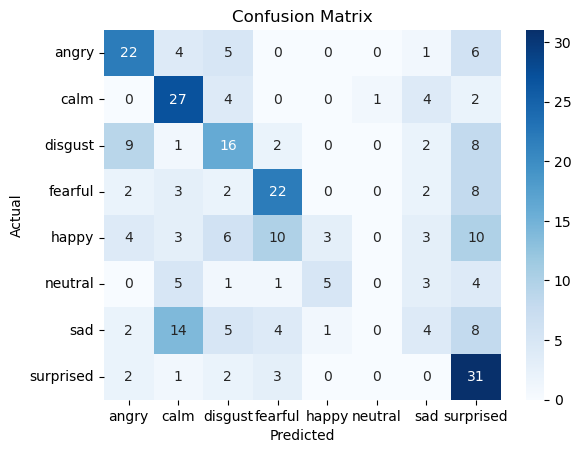

In [39]:
# Evaluate the Model Using Accuracy, F1-Score, and Confusion Matrix
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred, average="macro"))

print(classification_report(
    y_test, y_pred, target_names=encoder.classes_
))

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [40]:
#Predict the Emotion and Confidence Score of an Audio Sample
sample_path = files[0]

mfcc = extract_mfcc(sample_path)
mfcc = mfcc[np.newaxis, ..., np.newaxis]

prediction = model.predict(mfcc, verbose=0)[0]
emotion = encoder.inverse_transform([np.argmax(prediction)])[0]

print("Predicted Emotion:", emotion)
print("Confidence:", round(float(np.max(prediction)) * 100, 2), "%")

Predicted Emotion: surprised
Confidence: 30.49 %


In [43]:
#Perform Speech-to-Text Conversion Using Whisper
from transformers import pipeline
import librosa
import numpy as np

transcriber = pipeline(
    "automatic-speech-recognition",
    model="openai/whisper-tiny.en"
)
audio, sr = librosa.load(sample_path, sr=16000)

result = transcriber({
    "raw": audio.astype(np.float32),
    "sampling_rate": sr
})
text = result["text"]
print("Recognized Speech:", text)


Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> to see related `.generate()` flags.
[transformers] A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> will take precede

Recognized Speech:  Kids are talking by the door.


In [44]:
#Perform Text-to-Speech Conversion Using gTTS
from gtts import gTTS
from IPython.display import Audio, display

result = f"The recognized speech is {text}. The predicted emotion is {emotion}."

tts = gTTS(result, lang="en")
tts.save("output.mp3")

display(Audio("output.mp3"))

In [45]:
#  Save the Trained CNN Model for Future Use
model.save("audio_emotion_model.keras")
print("Model saved successfully.")

Model saved successfully.
